# Intersect `boreal` and `hydrobasins` for landscape analysis across boreal

In [10]:
import geopandas as gpd
import pandas as pd
from shapely.geometry import box

In [ ]:
HYBAS_FULL_HILAT_FN = '/projects/my-public-bucket/databank/hydrobasins/hybas_lake_hilat40N_75N_lev08_v1c_boreal_ecoregions.gpkg'

In [ ]:
BOREAL_DOMAIN_FN = '/projects/my-public-bucket/databank/arc/wwf_circumboreal_Dissolve.shp'

In [25]:
WWF_ECOREGIONS_FN = '/projects/my-public-bucket/databank/wwf_terr_ecos.gpkg'

In [3]:
boreal_gdf = gpd.read_file(BOREAL_DOMAIN_FN).to_crs(4326)

In [26]:
ecoregions_gdf = gpd.read_file(WWF_ECOREGIONS_FN)

In [19]:
# Define bounding box in 4326 and convert to your Albers CRS
bbox_4326 = box(-180, 42.5, 180, 75)  # Replace with your coordinates
bbox_gdf = gpd.GeoDataFrame([1], geometry=[bbox_4326], crs='EPSG:4326')

In [20]:
northern_boreal = gpd.overlay(boreal_gdf, bbox_gdf, how='union')

In [21]:
northern_boreal

,OBJECTID,REALM,Shape_Leng,Shape_Area,0,geometry
0,1.0,NA,8.945199e+07,6.536703e+12,1,"MULTIPOLYGON (((-80.07336 45.32933, -80.06914 ..."
1,2.0,PA,1.386740e+08,1.254836e+13,1,"MULTIPOLYGON (((168.03862 54.5743, 168.01861 5..."
2,NaN,NaN,NaN,NaN,1,"MULTIPOLYGON (((-180 75, 180 75, 180 42.5, -18..."


<Axes: >

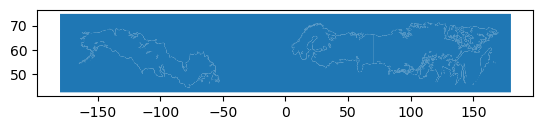

In [22]:
northern_boreal.plot()

In [24]:
# Alternative method if you want to preserve all hydrobasin attributes
def union_and_dissolve_preserve_attributes(hydrobasins_gdf, boreal_gdf):
    """
    Union with boreal and dissolve while preserving hydrobasin attributes
    """
    
    # Ensure same CRS
    if hydrobasins_gdf.crs != boreal_gdf.crs:
        boreal_gdf = boreal_gdf.to_crs(hydrobasins_gdf.crs)
    
    # Create union
    union_gdf = gpd.overlay(hydrobasins_gdf, boreal_gdf, how='union')
    
    # Get original hydrobasin attributes (excluding geometry)
    hydro_attrs = hydrobasins_gdf.drop(columns='geometry').drop_duplicates(subset=['HYBAS_ID'])
    
    # Dissolve by HYBAS_ID 
    dissolved_gdf = union_gdf.dissolve(by='HYBAS_ID', as_index=False)
    
    # Merge back the original attributes
    result_gdf = dissolved_gdf.merge(hydro_attrs, on='HYBAS_ID', how='left')
    
    return result_gdf

def union_and_label_boreal_hydrobasins(hydrobasins_gdf, boreal_gdf):
    """
    Union hydrobasins with boreal domain and label the boreal portions
    """
    # Ensure same CRS
    if hydrobasins_gdf.crs != boreal_gdf.crs:
        boreal_gdf = boreal_gdf.to_crs(hydrobasins_gdf.crs)
    
    # Step 1: Create a unified boreal geometry
    boreal_union = boreal_gdf.dissolve().geometry.iloc[0]
    
    # Step 2: Find hydrobasins that intersect with boreal
    intersecting_mask = hydrobasins_gdf.geometry.intersects(boreal_union)
    intersecting_basins = hydrobasins_gdf[intersecting_mask].copy()
    non_intersecting_basins = hydrobasins_gdf[~intersecting_mask].copy()
    
    # Step 3: For intersecting basins, split into boreal and non-boreal parts
    boreal_parts = []
    non_boreal_parts = []
    
    for idx, row in intersecting_basins.iterrows():
        basin_geom = row.geometry
        
        # Get boreal portion (intersection)
        boreal_intersection = basin_geom.intersection(boreal_union)
        
        # Get non-boreal portion (difference)
        non_boreal_difference = basin_geom.difference(boreal_union)
        
        # Add boreal part if it exists and has area
        if not boreal_intersection.is_empty and boreal_intersection.area > 0:
            boreal_row = row.copy()
            boreal_row.geometry = boreal_intersection
            boreal_row['boreal_label'] = 'boreal'
            boreal_row['original_basin_id'] = idx  # Keep track of original basin
            boreal_parts.append(boreal_row)
        
        # Add non-boreal part if it exists and has area
        if not non_boreal_difference.is_empty and non_boreal_difference.area > 0:
            non_boreal_row = row.copy()
            non_boreal_row.geometry = non_boreal_difference
            non_boreal_row['boreal_label'] = 'non_boreal'
            non_boreal_row['original_basin_id'] = idx
            non_boreal_parts.append(non_boreal_row)
    
    # Step 4: Add labels to non-intersecting basins
    non_intersecting_basins['boreal_label'] = 'non_boreal'
    non_intersecting_basins['original_basin_id'] = non_intersecting_basins.index
    
    # Step 5: Combine all parts
    all_parts = []
    
    if boreal_parts:
        all_parts.append(gpd.GeoDataFrame(boreal_parts, crs=hydrobasins_gdf.crs))
    
    if non_boreal_parts:
        all_parts.append(gpd.GeoDataFrame(non_boreal_parts, crs=hydrobasins_gdf.crs))
    
    all_parts.append(non_intersecting_basins)
    
    # Combine into final GeoDataFrame
    result_gdf = gpd.GeoDataFrame(pd.concat(all_parts, ignore_index=True), 
                                  crs=hydrobasins_gdf.crs)
    
    return result_gdf

def union_and_label_hydrobasins_multi(hydrobasins_gdf, boreal_gdf, ecoregion_gdf, 
                                     ecoregion_name_col='ECO_NAME'):
    """
    Union hydrobasins with both boreal domain and ecoregions, creating labels for both
    
    Parameters:
    -----------
    hydrobasins_gdf : GeoDataFrame
        The hydrobasins to process
    boreal_gdf : GeoDataFrame  
        The boreal domain polygons
    ecoregion_gdf : GeoDataFrame
        The ecoregion polygons
    ecoregion_name_col : str
        Column name in ecoregion_gdf that contains ecoregion names
    """
    
    # Ensure all GDFs have the same CRS
    target_crs = hydrobasins_gdf.crs
    if boreal_gdf.crs != target_crs:
        boreal_gdf = boreal_gdf.to_crs(target_crs)
    if ecoregion_gdf.crs != target_crs:
        ecoregion_gdf = ecoregion_gdf.to_crs(target_crs)
    
    # Step 1: Add identifier columns to the reference datasets
    boreal_labeled = boreal_gdf.copy()
    boreal_labeled['is_boreal'] = True
    
    ecoregion_labeled = ecoregion_gdf.copy()
    # Keep the ecoregion name/ID for labeling
    
    # Step 2: Sequential overlay operations
    # First overlay with boreal
    temp_result = gpd.overlay(hydrobasins_gdf, boreal_labeled, how='union')
    
    # Then overlay with ecoregions
    final_result = gpd.overlay(temp_result, ecoregion_labeled, how='union')
    
    # Step 3: Create labels
    # Boreal label
    final_result['boreal_label'] = final_result['is_boreal'].fillna(False).map({
        True: 'boreal', 
        False: 'non_boreal'
    })
    
    # Ecoregion label
    final_result['ecoregion_label'] = final_result[ecoregion_name_col].fillna('no_ecoregion')
    
    # Step 4: Clean up temporary columns
    columns_to_drop = ['is_boreal']
    # Also drop any duplicate ecoregion columns that might have been created
    columns_to_drop.extend([col for col in final_result.columns if col.endswith('_2')])
    
    final_result = final_result.drop(columns=[col for col in columns_to_drop if col in final_result.columns])
    
    return final_result

In [ ]:
# File paths
files = [
        '/projects/my-public-bucket/databank/hydrobasins/hybas_lake_ar_lev08_v1c.shp', 
         '/projects/my-public-bucket/databank/hydrobasins/hybas_lake_na_lev08_v1c.shp', 
         '/projects/my-public-bucket/databank/hydrobasins/hybas_lake_si_lev08_v1c.shp',
        '/projects/my-public-bucket/databank/hydrobasins/hybas_lake_eu_lev08_v1c.shp',
         '/projects/my-public-bucket/databank/hydrobasins/hybas_lake_as_lev08_v1c.shp',
        ]

# Read, filter, and concatenate
selected_gdfs = []

for file in files:
    gdf = gpd.read_file(file)

    # Intersection box (leaves you with northern but non-boreal hydrobasins)
    hybas_intersecting_box = gpd.sjoin(gdf, bbox_gdf, how='inner', predicate='intersects')
    # Union with boreal - should cut across landscapes that straddle the boreal, creating boreal and non-boreal 
    hybas_intersecting_boreal = union_and_label_hydrobasins_multi(hybas_intersecting_box, boreal_gdf, ecoregions_gdf)
    
    selected_gdfs.append(hybas_intersecting_boreal.drop('index_right', axis=1))

# Concatenate all selected polygons
result_gdf = gpd.GeoDataFrame(pd.concat(selected_gdfs, ignore_index=True))

In [ ]:
result_gdf.shape

In [ ]:
result_gdf.plot(column='boreal_label')

In [ ]:
result_gdf = result_gdf.drop(result_gdf.columns[-1], axis=1)

In [ ]:
result_gdf.to_file(HYBAS_FULL_HILAT_FN, driver='GPKG')